Set Up

In [1]:
import pandas as pd
import numpy as np
import shap
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
import xgboost as xgb

PROCESSED = Path("../processed")
FIGURES   = Path("../figures")
MODELS    = Path("../models")

# Load model and data
model = xgb.XGBClassifier()
model.load_model(MODELS / "xgb_fraud_model.json")

df = pd.read_parquet(PROCESSED / "data_processed.parquet")

with open(PROCESSED / "selected_features.json", "r") as f:
    top_features = json.load(f)

with open(PROCESSED / "optimal_threshold.json", "r") as f:
    optimal_config = json.load(f)

optimal_threshold = optimal_config["optimal_threshold"]

# Recreate test set (same temporal split as notebook 04)
df = df.sort_values("day").reset_index(drop=True)
X = df[top_features]
y = df["isFraud"]

n = len(df)
X_test = X.iloc[int(n * 0.85):]
y_test = y.iloc[int(n * 0.85):]

print(f"Test shape: {X_test.shape}")
print(f"Optimal threshold: {optimal_threshold}")

Test shape: (88581, 74)
Optimal threshold: 0.13


SHAP Explainer

In [2]:

explainer = shap.TreeExplainer(model)


sample_size = 2000
X_sample = X_test.sample(n=sample_size, random_state=42)

shap_values = explainer.shap_values(X_sample)

print(f"SHAP values shape: {shap_values.shape}")
print("SHAP computation complete.")

SHAP values shape: (2000, 74)
SHAP computation complete.


Global Feature Importance

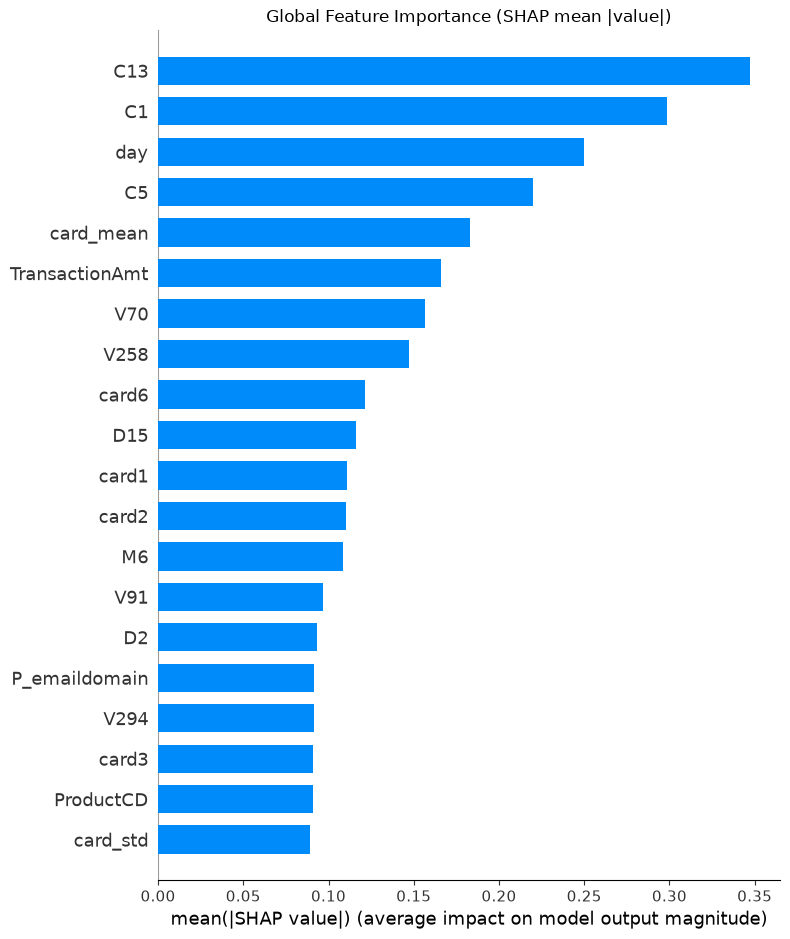

In [3]:
plt.figure()
shap.summary_plot(
    shap_values, X_sample,
    max_display=20,
    show=False,
    plot_type="bar"
)
plt.title("Global Feature Importance (SHAP mean |value|)")
plt.tight_layout()
plt.savefig(FIGURES / "11_shap_global_bar.png", dpi=150, bbox_inches="tight")
plt.show()

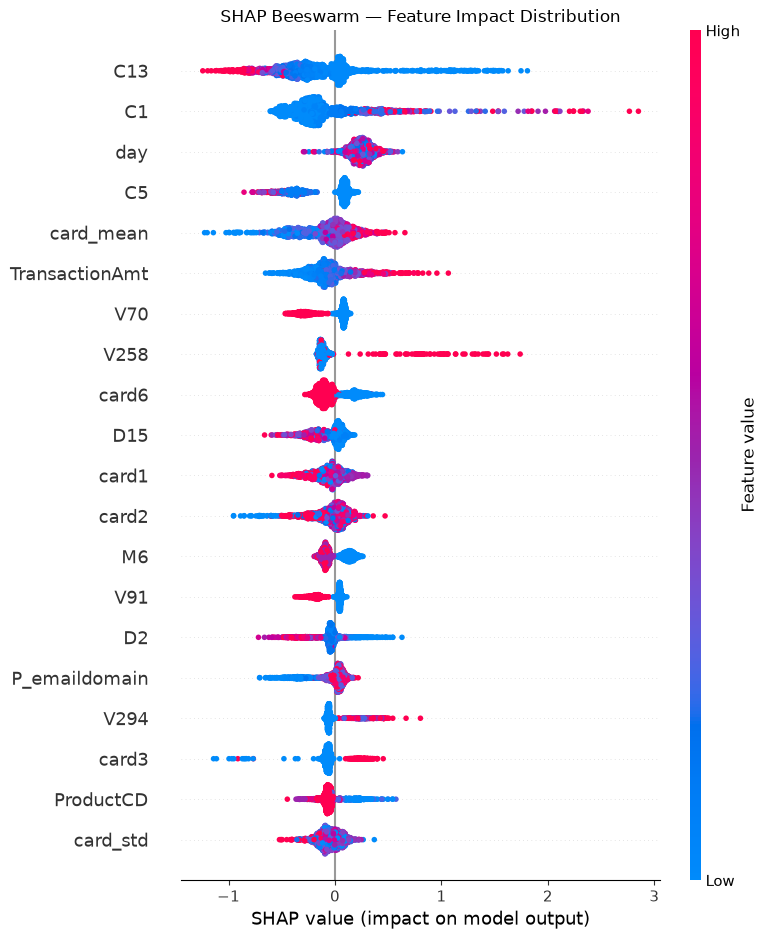

In [4]:
plt.figure()
shap.summary_plot(
    shap_values, X_sample,
    max_display=20,
    show=False
)
plt.title("SHAP Beeswarm — Feature Impact Distribution")
plt.tight_layout()
plt.savefig(FIGURES / "12_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

Local Explanation: Fraud Transaction

Explaining fraud transaction at index: 525995
Predicted probability: 0.0524


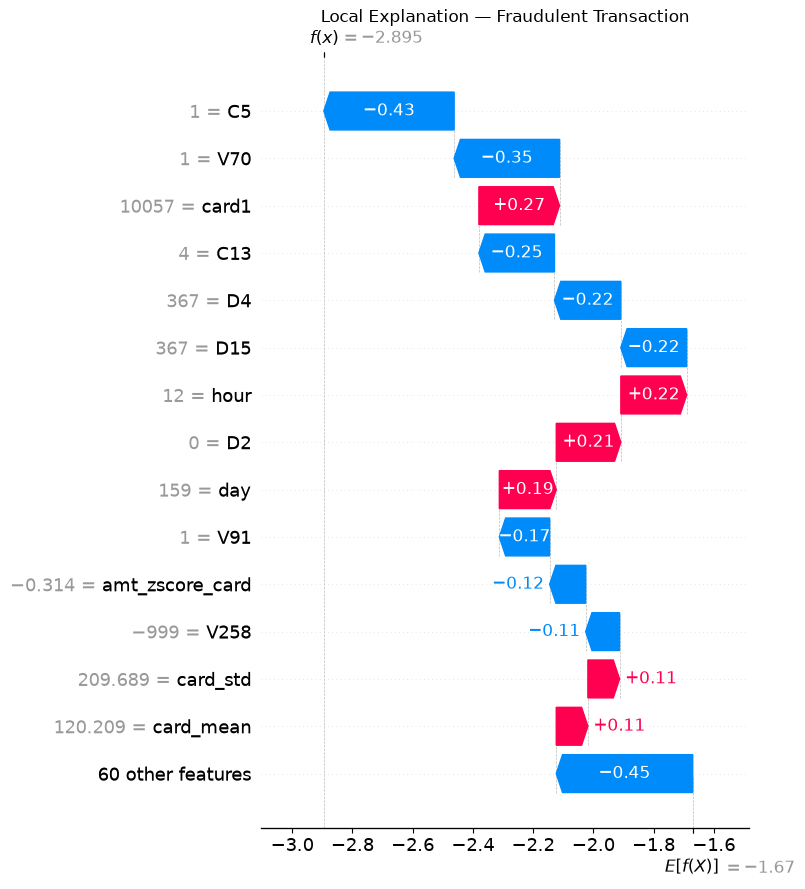

In [5]:

y_sample = y_test.loc[X_sample.index]
fraud_idx = y_sample[y_sample == 1].index[0]
fraud_pos = X_sample.index.get_loc(fraud_idx)

print(f"Explaining fraud transaction at index: {fraud_idx}")
print(f"Predicted probability: {model.predict_proba(X_sample.iloc[[fraud_pos]])[:, 1][0]:.4f}")

plt.figure()
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[fraud_pos],
        base_values=explainer.expected_value,
        data=X_sample.iloc[fraud_pos],
        feature_names=top_features
    ),
    max_display=15,
    show=False
)
plt.title("Local Explanation — Fraudulent Transaction")
plt.tight_layout()
plt.savefig(FIGURES / "13_shap_local_fraud.png", dpi=150, bbox_inches="tight")
plt.show()

Local Explanation: Legitimate Transaction


Explaining legitimate transaction at index: 526093
Predicted probability: 0.0344


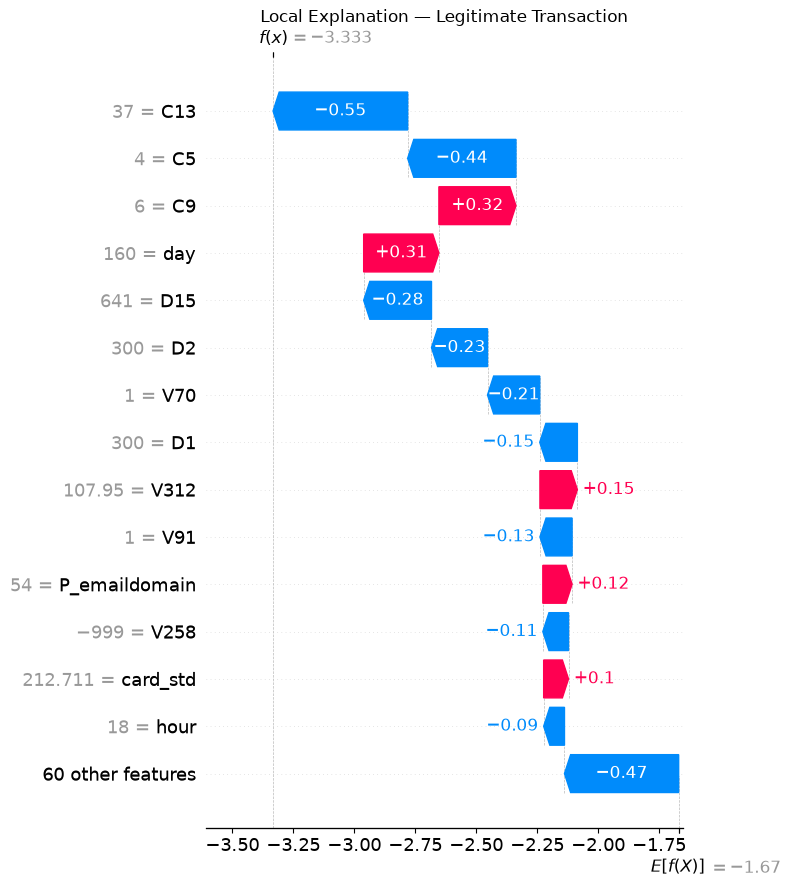

In [6]:

legit_idx = y_sample[y_sample == 0].index[0]
legit_pos = X_sample.index.get_loc(legit_idx)

print(f"Explaining legitimate transaction at index: {legit_idx}")
print(f"Predicted probability: {model.predict_proba(X_sample.iloc[[legit_pos]])[:, 1][0]:.4f}")

plt.figure()
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[legit_pos],
        base_values=explainer.expected_value,
        data=X_sample.iloc[legit_pos],
        feature_names=top_features
    ),
    max_display=15,
    show=False
)
plt.title("Local Explanation — Legitimate Transaction")
plt.tight_layout()
plt.savefig(FIGURES / "14_shap_local_legit.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
np.save(PROCESSED / "shap_values.npy", shap_values)
np.save(PROCESSED / "shap_sample_index.npy", X_sample.index.values)

print("Saved: shap_values.npy, shap_sample_index.npy")

Saved: shap_values.npy, shap_sample_index.npy


## Summary

- Used `shap.TreeExplainer` on a 2,000-transaction sample from the test set.
- **Global importance (beeswarm)**: C13, C1, day, C5, card_mean are the 
  strongest fraud signals — C features represent transaction count features 
  that capture behavioral patterns (how many transactions of each type has 
  this card made).
- **Consistency with feature selection**: top SHAP features are consistent 
  with SHAP CV selection (C13, C14, card_mean, card6) — confirms selection 
  was robust.
- **V258**: high values push strongly toward fraud (red dots right of zero) 
  — Vesta's proprietary feature is a reliable fraud signal when present.
- **E[f(X)] = -1.67**: base model output improved vs previous iteration 
  (-4.39) — scale_pos_weight correction produced better-calibrated predictions.
- **Local explanation (fraud case)**: False Negative — V258 = -999 (missing 
  V block). Pattern observed across multiple FN cases: missing Vesta features 
  reduce fraud signal. Production rule recommended: flag transactions with 
  missing V blocks for separate review regardless of model score.
- **Local explanation (legitimate case)**: correctly classified. C13=37 and 
  C5=4 are strong legitimacy signals — high transaction count history 
  indicates established customer behavior.
- **GDPR relevance**: SHAP waterfall plots provide transaction-level 
  explanations required under EU automated decision-making regulation.

**Outputs:** `shap_values.npy`, `shap_sample_index.npy`, 
`figures/11-14_shap_*.png`